# Solving a simple durable–nondurable model with EV Type I taste shocks

Step-by-step solution of the **Extreme Value Type I taste-shock extension** of the basic durable model from
`Text/DurableModelBasic.tex` §"Extension: Extreme Value Type I Taste Shocks" (derivations in
`Text/ApndxDurableModelBasic.tex` §"Derivations: Extreme Value Type I Taste Shocks"):
- $LTV=0$, $\underline{a}=0$ (no borrowing)
- No maintenance / operation costs
- No permanent shocks / growth / unemployment
- Single interest rate $\mathcal{R}=1+r$
- Adjustment cost $\tau$ retained
- i.i.d. **EV Type I (Gumbel) taste shocks** on keep vs adjust, integrated out in closed form
  via the log-sum inclusive value and logit choice probabilities
  (scale $\sigma_\varepsilon$; collapses to hard max as $\sigma_\varepsilon\to 0$);
  no search frictions (see `DurableModel_Search_One_Period.ipynb` for that extension)
- No limit / frictionless extrapolation function

Code is adapted from `BackgroundInformation/DurableModel_Fast_Latest.py` and
`Code/DurableModel_One_Period.ipynb`, simplified. The discrete combine step mirrors
`calcLogSumChoiceProbs(..., smoothtype='type1')` in `Code/Endogenous-Retirement-Search-v3.py`.


In [1]:
# --- Imports and path setup ---
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import scipy.optimize as sp_optimize

ROOT = Path.cwd().resolve()
if ROOT.name == "Code":
    BG = ROOT.parent / "BackgroundInformation"
else:
    BG = ROOT / "BackgroundInformation"
sys.path.insert(0, str(BG))

from HARK.econforgeinterp import LinearFast
from HARK.interpolation import ValueFuncCRRA, LowerEnvelope2D, MargValueFuncCRRA
from HARK.ConsumptionSaving.ConsIndShockModel import utility, utility_inv, utilityP_inv
from HARK.dcegm import calc_nondecreasing_segments, upper_envelope
from HARK.distribution import expected
from HARK.utilities import make_grid_exp_mult

from FUES import FUES_allPol
from utilities_Durable import (
    construct_grid,
    CRRAutilityP_inv_njit,
    CRRAutility_njit,
    MargValueFuncCRRA_dur,
    inv_MargValueFuncCRRA_dur,
    find_roots_in_interval,
    durable_solution_function_FUES_fast_search_noSS,
    HANKIncShkDstn_Truncated,
    vp_next_vPDFunc,
    vFunc_next,
    update_prob_grid_list_with_trunc,
)

np.set_printoptions(precision=4, suppress=True)
print("Imports OK")


Imports OK


## Parameters

Simplified relative to the full model: $LTV=0$, $\underline{a}=0$, $\chi=\textit{OpCost}=0$, $\textit{SearchCost}=0$, no permanent risk.

In [2]:
# --- Preferences ---
CRRA = 2.0
DiscFac = 0.975
LivPrb = 1.0
alpha = 0.75         # Cobb-Douglas share on nondurables
d_ubar = 1e-4        # utility floor on durables (not a borrowing bound)

# --- Durables / frictions ---
dDepr = 0.05         # delta
adjC = 0.3          # tau (keep > 0 so keep vs adjust is nontrivial)
tau = adjC           # constant adjustment cost
MaintCost = 0.0
OpCost = 0.0

# --- Returns / borrowing (basic model) ---
Rfree = 1.04**(0.25)         # single gross interest factor R
RSpread = 0.0
PermGroFac = 1.0     # no permanent-income growth (still passed into EoP formulas)
LTV = 0.0
BoroCnstArt = 0.0    # a underbar

# --- Income shocks: exact HANKIncShkDstn_Truncated construction ---
# Basic model: no permanent shocks, no unemployment
PermShkStd = 0.0
PermShkCount = 1
TranShkStd = 0.2
TranShkCount = 7
UnempPrb = 0.0
IncUnemp = 0.0
truncation = 2
taxrate = 0.0
labor = 1.0
wage = 1.0

# --- EV Type I taste shocks on keep vs adjust (Section "Extension: Extreme Value Type I Taste Shocks") ---
# Additive i.i.d. Gumbel shocks with scale sigma_eps; closed-form log-sum / logit combine.
# sigma_eps -> 0 collapses to the hard-max baseline (no quadrature nodes needed).
sigma_eps = 0.05      # taste-shock scale (sigma in calcLogSumChoiceProbs / type1)

def TranShkMean_Func(taxrate, labor, wage):
    """Same as DurableModel_Fast_Latest.TranShkMean_Func."""
    return (1.0 - taxrate) * labor * wage

# --- EoP integration method (exactly one must be True) ---
use_expected = True            # HARK expected() over IncShkDstn
use_TransitionMatrix = False   # b->m lottery / transition-matrix method
assert use_expected ^ use_TransitionMatrix, (
    "Set exactly one of use_expected / use_TransitionMatrix to True"
)

# --- Grids (modest for a notebook) ---
nNrmMax, nNrmCount = 5.0, 100
mNrmMax, mNrmCount = 8.0, 100
xNrmMax, xNrmCount = 13.0, 200
aNrmMax, aNrmCount = 8.0, 100
aXtraMax = aNrmMax  # used for TransitionMatrix m/b span (as in full model)
NestFac = 1
grid_type = "exp_mult"
tol_combine = 1e-4

# TransitionMatrix dense grids (same construction as updatem/bNrmGrid_income)
TranMatrix_mCount = 1010
TranMatrix_bCount = 1000

# --- Utility closures (from DurableModel_Fast_Latest.def_utility_funcs) ---
def CRRAutility(C, D):
    u_inner = (C ** alpha) * ((D + d_ubar) ** (1.0 - alpha))
    return utility(u_inner, CRRA)

def CRRAutility_inv(C, D):
    return utility_inv(CRRAutility(C, D), CRRA)

def CRRAutilityP(C, D):
    return (alpha * C ** (alpha * (1.0 - CRRA) - 1.0)
            * (D + d_ubar) ** ((1.0 - alpha) * (1.0 - CRRA)))

def CRRAutilityPD(C, D):
    return ((1.0 - alpha) * (C ** (alpha * (1.0 - CRRA)))
            * (D + d_ubar) ** ((1.0 - alpha) * (1.0 - CRRA) - 1.0))

def CRRAutilityP_inv(Cmarg, D):
    power = 1.0 / (alpha * (1.0 - CRRA) - 1.0)
    return (Cmarg / (alpha * (D + d_ubar) ** ((1.0 - alpha) * (1.0 - CRRA)))) ** power

def tau_func(x):
    """Constant adjustment cost (ScaleBool=False in the full model)."""
    return np.ones_like(np.asarray(x, dtype=float)) * tau

print("Parameters set.")
print("EoP method:", "expected" if use_expected else "TransitionMatrix")


Parameters set.
EoP method: expected


## EV Type I discrete combine

No taste-shock quadrature grid is needed. The inclusive value and logit probabilities
are the closed-form log-sum / softmax of the two conditional values (keep, adjust),
matching `calcLogSumChoiceProbs(..., smoothtype='type1')` in
`Code/Endogenous-Retirement-Search-v3.py` and eqs. (taste_logsum)–(taste_logit) in
`Text/DurableModelBasic.tex`.


In [3]:
# --- EV Type I log-sum / logit combine (calcLogSumChoiceProbs, smoothtype="type1") ---
def calcLogSumChoiceProbs(Vals, sigma):
    """
    Inclusive value and choice probabilities for i.i.d. EV Type I taste shocks.

    Non-finite entries (-inf / nan) are treated as infeasible. Replacing them before
    the log-sum is essential: otherwise (-inf)-(-inf) yields NaN when every branch
    is infeasible at a grid point (e.g. m=0 corners).
    """
    Vals = np.asarray(Vals, dtype=float)
    if sigma == 0.0:
        Vals_rank = np.where(np.isfinite(Vals), Vals, -np.inf)
        Pflat = np.argmax(Vals_rank, axis=0)
        V = np.full(Vals[0].shape, -np.inf)
        Probs = np.zeros(Vals.shape)
        for i in range(Vals.shape[0]):
            optimal = Pflat == i
            V[optimal] = Vals_rank[i][optimal]
            Probs[i][optimal] = 1.0
        return V, Probs

    finite = np.isfinite(Vals)
    Vals_work = np.where(finite, Vals, -1.0e300)
    maxV = np.max(Vals_work, axis=0)
    sumexp = np.sum(np.exp((Vals_work - maxV) / sigma), axis=0)
    LogSumV = maxV + sigma * np.log(sumexp)
    Probs = np.exp((Vals_work - LogSumV) / sigma)

    all_bad = ~np.any(finite, axis=0)
    LogSumV = np.where(all_bad, -np.inf, LogSumV)
    Probs = np.where(all_bad, 0.0, Probs)
    Probs = np.where(finite, Probs, 0.0)
    mass = Probs.sum(axis=0, keepdims=True)
    Probs = np.where(mass > 0.0, Probs / np.where(mass > 0.0, mass, 1.0), Probs)
    return LogSumV, Probs


def combine_ev_taste_shock(
    vAdj_level, vKeep_level,
    cAdj, dAdj, aAdj, vPAdj, vPDAdj,
    cKeep, dKeep, aKeep, vPKeep, vPDKeep,
    sigma,
):
    """
    Combine keep vs adjust with EV Type I taste shocks on a grid of (n,m).

    Follows Text/ApndxDurableModelBasic.tex §"Derivations: Extreme Value Type I Taste Shocks":
        v = sigma * log(exp(vKeep/sigma) + exp(vAdj/sigma))
        P^adj = exp(vAdj/sigma) / (exp(vKeep/sigma) + exp(vAdj/sigma))
        v_m = P^keep * vPKeep + P^adj * vPAdj
    Expected policies are probability-weighted averages of the two branches.
    """
    Vals = np.stack([vKeep_level, vAdj_level], axis=0)
    V, Probs = calcLogSumChoiceProbs(Vals, sigma)
    Pkeep, Padj = Probs[0], Probs[1]

    def mix_marg(P0, x0, P1, x1):
        """Probability-weighted mix; propagate +inf when a positive-prob branch is non-finite."""
        bad = ((P0 > 0) & ~np.isfinite(x0)) | ((P1 > 0) & ~np.isfinite(x1))
        x0s = np.where(np.isfinite(x0), x0, 0.0)
        x1s = np.where(np.isfinite(x1), x1, 0.0)
        return np.where(bad, np.inf, P0 * x0s + P1 * x1s)

    barV = V
    barVP = mix_marg(Pkeep, vPKeep, Padj, vPAdj)
    barVPD = mix_marg(Pkeep, vPDKeep, Padj, vPDAdj)
    barC = Pkeep * cKeep + Padj * cAdj
    barD = Pkeep * dKeep + Padj * dAdj
    barA = Pkeep * aKeep + Padj * aAdj
    barAdjProb = Padj
    return barV, barVP, barVPD, barC, barD, barA, barAdjProb


print(f"EV Type I taste-shock scale sigma_eps = {sigma_eps}")


EV Type I taste-shock scale sigma_eps = 0.05


## Grids

In [4]:
# nNrmGrid
nNrmGrid = construct_grid(0.001, nNrmMax, nNrmCount - 1, grid_type, NestFac)
nNrmGrid = np.unique(np.append(0.0, nNrmGrid))

# mNrmGrid
mNrmGrid = construct_grid(0.001, mNrmMax, mNrmCount - 1, grid_type, NestFac)
mNrmGrid = np.unique(np.append(0.0, mNrmGrid))

# xNrmGrid (liquidity = m + (1-tau)n)
xNrmGrid = construct_grid(0.001, xNrmMax, xNrmCount - 1, grid_type, NestFac)
xNrmGrid = np.unique(np.append(0.0, xNrmGrid))

# aNrmGrid (a >= 0)
aNrmGrid = construct_grid(0.001, aNrmMax, aNrmCount - 1, grid_type, NestFac)
aNrmGrid = np.unique(np.append(0.0, aNrmGrid))

# End-of-period durable grid (same span as n)
dNrmGrid = nNrmGrid.copy()

print(f"n: {len(nNrmGrid)}, m: {len(mNrmGrid)}, x: {len(xNrmGrid)}, a: {len(aNrmGrid)}")


n: 100, m: 100, x: 200, a: 100


In [5]:
# --- Plotting helper used after each solution step ---
def plot_keeper_adjuster_combined(
    n_vals,
    m_grid,
    c_keep, d_keep, inv_v_keep,
    c_adj, d_adj, inv_v_adj,
    c_comb, d_comb, inv_v_comb,
    adjusting=None,
    title="",
):
    """Plot c, d, and inv_v vs m for a few n, for keeper / adjuster / combined."""
    n_plot = np.atleast_1d(n_vals)
    fig, axes = plt.subplots(3, 3, figsize=(14, 9), sharex=True)
    titles = ["Keeper", "Adjuster", "Combined"]
    c_funcs = [c_keep, c_adj, c_comb]
    d_funcs = [d_keep, d_adj, d_comb]
    inv_vfuncs = [inv_v_keep, inv_v_adj, inv_v_comb]

    for col, (ttl, cf, df, ivf) in enumerate(zip(titles, c_funcs, d_funcs, inv_vfuncs)):
        for n0 in n_plot:
            n_vec = np.full_like(m_grid, n0, dtype=float)
            axes[0, col].plot(m_grid, cf(n_vec, m_grid), label=fr"$n={n0:.2f}$")
            axes[1, col].plot(m_grid, df(n_vec, m_grid), label=fr"$n={n0:.2f}$")
            axes[2, col].plot(m_grid, ivf(n_vec, m_grid), label=fr"$n={n0:.2f}$")
        axes[0, col].set_title(ttl)
        axes[0, col].set_ylabel(r"$c(n,m)$")
        axes[1, col].set_ylabel(r"$d(n,m)$")
        axes[2, col].set_ylabel(r"$\mathrm{inv}\,v(n,m)$")
        axes[2, col].set_xlabel(r"$m$")
        axes[0, col].legend(fontsize=8)
        axes[1, col].legend(fontsize=8)
        axes[2, col].legend(fontsize=8)

    if adjusting is not None:
        ax = axes[0, 2].twinx()
        n0 = n_plot[len(n_plot) // 2]
        n_vec = np.full_like(m_grid, n0, dtype=float)
        ax.plot(m_grid, adjusting(n_vec, m_grid), "k--", alpha=0.4, label="adjusting")
        ax.set_ylabel("adjusting")
        ax.set_ylim(-0.05, 1.05)

    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


In [6]:
def plot_adjusting_heatmap(nGrid, mGrid, array, title, cbar_label="adjusting"):
    """
    2-D heatmap of the (discrete or soft) adjusting indicator over the (n,m) grid:
    m on the x-axis, n on the y-axis, color scale fixed to [0,1].
    """
    fig, ax = plt.subplots(figsize=(7, 5))
    pcm = ax.pcolormesh(mGrid, nGrid, array, cmap="viridis", shading="auto", vmin=0.0, vmax=1.0)
    fig.colorbar(pcm, ax=ax, label=cbar_label)
    ax.set_xlabel(r"$m$")
    ax.set_ylabel(r"$n$")
    ax.set_title(title)
    fig.tight_layout()
    plt.show()


## Terminal period

Continuation value is zero. With $LTV=0$ and $\underline{a}=0$, both types set $a=0$.
- **Keeper:** $d=n$, $c=m$
- **Adjuster:** $c=\alpha\ell$, $d=(1-\alpha)\ell$ with $\ell=m+(1-\tau)n$
- **Combined:** EV Type I inclusive value
  $v_T=\sigma_\varepsilon\log\big(\exp(v_T^{\mathrm{keep}}/\sigma_\varepsilon)+\exp(v_T^{\mathrm{adj}}/\sigma_\varepsilon)\big)$
  (eq.~taste_logsum), with logit-weighted expected policies


In [7]:
# ===== Terminal: Keeper =====
# From solve_terminal_solution (LTV=0 branch): c=m, d=n, a=0
mNrmGrid_T = np.append(mNrmGrid, mNrmGrid[-1] + 1.0)
nNrmGrid_T = nNrmGrid.copy()

keep_shape = (len(nNrmGrid_T), len(mNrmGrid_T))
cFuncKeep_T_arr = np.zeros(keep_shape)
dFuncKeep_T_arr = np.zeros(keep_shape)
aFuncKeep_T_arr = np.zeros(keep_shape)
inv_vFuncKeep_T_arr = np.zeros(keep_shape)

for i_n, n0 in enumerate(nNrmGrid_T):
    dFuncKeep_T_arr[i_n, :] = n0
    cFuncKeep_T_arr[i_n, :] = mNrmGrid_T
    aFuncKeep_T_arr[i_n, :] = mNrmGrid_T - cFuncKeep_T_arr[i_n, :]  # = 0
    inv_vFuncKeep_T_arr[i_n, :] = CRRAutility_inv(cFuncKeep_T_arr[i_n, :], dFuncKeep_T_arr[i_n, :])

vPFuncKeep_T_arr = CRRAutilityP(cFuncKeep_T_arr, dFuncKeep_T_arr)
vPDFuncKeep_T_arr = CRRAutilityPD(cFuncKeep_T_arr, dFuncKeep_T_arr)

cFuncKeep_T = LinearFast(cFuncKeep_T_arr, [nNrmGrid_T, mNrmGrid_T])
dFuncKeep_T = LinearFast(dFuncKeep_T_arr, [nNrmGrid_T, mNrmGrid_T])
inv_vFuncKeep_T = LinearFast(inv_vFuncKeep_T_arr, [nNrmGrid_T, mNrmGrid_T])
vFuncKeep_T = ValueFuncCRRA(inv_vFuncKeep_T, CRRA)
vPFuncKeep_T = MargValueFuncCRRA_dur(cFuncKeep_T, dFuncKeep_T, alpha, d_ubar, CRRA)

print("Terminal keeper done.")


Terminal keeper done.


c:\Users\amonninger\AppData\Local\miniconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:40: RuntimeWarning: divide by zero encountered in reciprocal
  return c ** (1.0 - rho) / (1.0 - rho)
C:\Users\amonninger\AppData\Local\Temp\ipykernel_13332\1342355393.py:74: RuntimeWarning: divide by zero encountered in power
  return (alpha * C ** (alpha * (1.0 - CRRA) - 1.0)
C:\Users\amonninger\AppData\Local\Temp\ipykernel_13332\1342355393.py:78: RuntimeWarning: divide by zero encountered in power
  return ((1.0 - alpha) * (C ** (alpha * (1.0 - CRRA)))


In [8]:
# ===== Terminal: Adjuster (analytical; LTV=0 => c=alpha*x, d=(1-alpha)*x) =====
# 1-D in liquidity x
cFuncAdj_T_1d = alpha * xNrmGrid
dFuncAdj_T_1d = (1.0 - alpha) * xNrmGrid
inv_vFuncAdj_T_1d = CRRAutility_inv(cFuncAdj_T_1d, dFuncAdj_T_1d)

cFuncAdj_T = LinearFast(cFuncAdj_T_1d, [xNrmGrid])
dFuncAdj_T = LinearFast(dFuncAdj_T_1d, [xNrmGrid])
inv_vFuncAdj_T = LinearFast(inv_vFuncAdj_T_1d, [xNrmGrid])
vFuncAdj_T = ValueFuncCRRA(inv_vFuncAdj_T, CRRA)
vPFuncAdj_T = MargValueFuncCRRA_dur(cFuncAdj_T, dFuncAdj_T, alpha, d_ubar, CRRA)

# Map adjuster onto (n,m)
shape_T = (len(nNrmGrid_T), len(mNrmGrid_T))
cFuncAdj_SOL_T = np.zeros(shape_T)
dFuncAdj_SOL_T = np.zeros(shape_T)
aFuncAdj_SOL_T = np.zeros(shape_T)
inv_vFuncAdj_SOL_T = np.zeros(shape_T)
vPDFuncAdj_SOL_T = np.zeros(shape_T)

for i_n, n0 in enumerate(nNrmGrid_T):
    n_aux = np.full(len(mNrmGrid_T), n0)
    tau_nm = tau_func(n_aux + mNrmGrid_T)
    x_aux = np.clip(mNrmGrid_T + (1.0 - tau_nm) * n_aux, 0.0, None)
    dFuncAdj_SOL_T[i_n, :] = (1.0 - alpha) * x_aux
    cFuncAdj_SOL_T[i_n, :] = alpha * x_aux
    aFuncAdj_SOL_T[i_n, :] = x_aux - cFuncAdj_SOL_T[i_n, :] - dFuncAdj_SOL_T[i_n, :]  # = 0
    inv_vFuncAdj_SOL_T[i_n, :] = CRRAutility_inv(cFuncAdj_SOL_T[i_n, :], dFuncAdj_SOL_T[i_n, :])
    vPDFuncAdj_SOL_T[i_n, :] = (1.0 - tau_nm) * CRRAutilityP(cFuncAdj_SOL_T[i_n, :], dFuncAdj_SOL_T[i_n, :])

vPFuncAdj_SOL_T = CRRAutilityP(cFuncAdj_SOL_T, dFuncAdj_SOL_T)

cFuncAdj_NM_T = LinearFast(cFuncAdj_SOL_T, [nNrmGrid_T, mNrmGrid_T])
dFuncAdj_NM_T = LinearFast(dFuncAdj_SOL_T, [nNrmGrid_T, mNrmGrid_T])

print("Terminal adjuster done.")


Terminal adjuster done.


C:\Users\amonninger\AppData\Local\Temp\ipykernel_13332\1342355393.py:74: RuntimeWarning: divide by zero encountered in power
  return (alpha * C ** (alpha * (1.0 - CRRA) - 1.0)


In [9]:
# ===== Terminal: EV Type I taste-shock combine =====
# Within-branch (c,d,a) optimizers do not depend on the Gumbel draws, so we apply the
# closed-form log-sum / logit combine to the level value/marginal-value functions.
vAdj_T_level = utility(inv_vFuncAdj_SOL_T, CRRA)
vKeep_T_level = utility(inv_vFuncKeep_T_arr, CRRA)

(
    barV_T_arr, barVP_T_arr, barVPD_T_arr,
    barC_T_arr, barD_T_arr, barA_T_arr, barAdjProb_T_arr,
) = combine_ev_taste_shock(
    vAdj_T_level, vKeep_T_level,
    cFuncAdj_SOL_T, dFuncAdj_SOL_T, aFuncAdj_SOL_T, vPFuncAdj_SOL_T, vPDFuncAdj_SOL_T,
    cFuncKeep_T_arr, dFuncKeep_T_arr, aFuncKeep_T_arr, vPFuncKeep_T_arr, vPDFuncKeep_T_arr,
    sigma_eps,
)

# Inclusive value and probability-weighted marginals (eqs. taste_logsum / taste_vm / taste_vn);
# store inverse-transformed for interpolation, exactly like the hard-max objects they replace.
cFunc_T = LinearFast(barC_T_arr, [nNrmGrid_T, mNrmGrid_T])   # expected policy (plotting only)
dFunc_T = LinearFast(barD_T_arr, [nNrmGrid_T, mNrmGrid_T])   # expected policy (plotting only)
inv_vFunc_T = LinearFast(utility_inv(barV_T_arr, CRRA), [nNrmGrid_T, mNrmGrid_T])
vFunc_T = ValueFuncCRRA(inv_vFunc_T, CRRA)
vPFunc_T = LinearFast(barVP_T_arr, [nNrmGrid_T, mNrmGrid_T])
vPDFunc_T = LinearFast(barVPD_T_arr, [nNrmGrid_T, mNrmGrid_T])
inv_vPFunc_T = LinearFast(utilityP_inv(barVP_T_arr, CRRA), [nNrmGrid_T, mNrmGrid_T])
inv_vPDFunc_T = LinearFast(utilityP_inv(barVPD_T_arr, CRRA), [nNrmGrid_T, mNrmGrid_T])
adjusting_T = LinearFast(barAdjProb_T_arr, [nNrmGrid_T, mNrmGrid_T])  # P^adj in (0,1)

print("Terminal EV taste-shock combine done. E[P^adj]:", barAdjProb_T_arr.mean())


Terminal EV taste-shock combine done. E[P^adj]: 0.6388917278475458


c:\Users\amonninger\AppData\Local\miniconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:184: RuntimeWarning: divide by zero encountered in power
  return uP ** (-1.0 / rho)


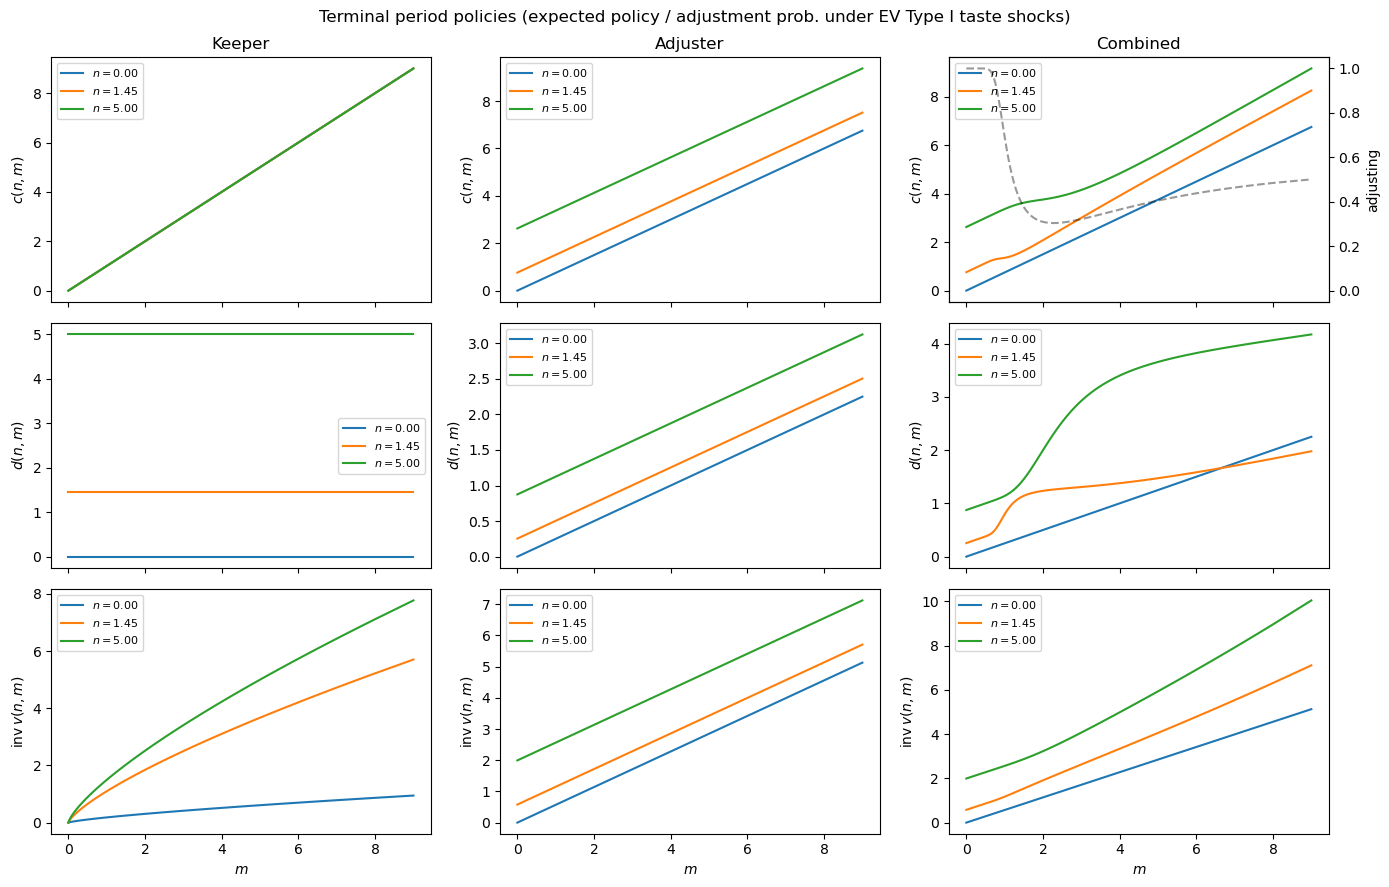

In [10]:
# --- Plot terminal policies ---
n_show = nNrmGrid_T[np.linspace(1, len(nNrmGrid_T) - 1, 3, dtype=int)]
inv_vFuncAdj_NM_T = LinearFast(inv_vFuncAdj_SOL_T, [nNrmGrid_T, mNrmGrid_T])
plot_keeper_adjuster_combined(
    n_show, mNrmGrid_T,
    cFuncKeep_T, dFuncKeep_T, inv_vFuncKeep_T,
    cFuncAdj_NM_T, dFuncAdj_NM_T, inv_vFuncAdj_NM_T,
    cFunc_T, dFunc_T, inv_vFunc_T,
    adjusting=adjusting_T,
    title="Terminal period policies (expected policy / adjustment prob. under EV Type I taste shocks)",
)




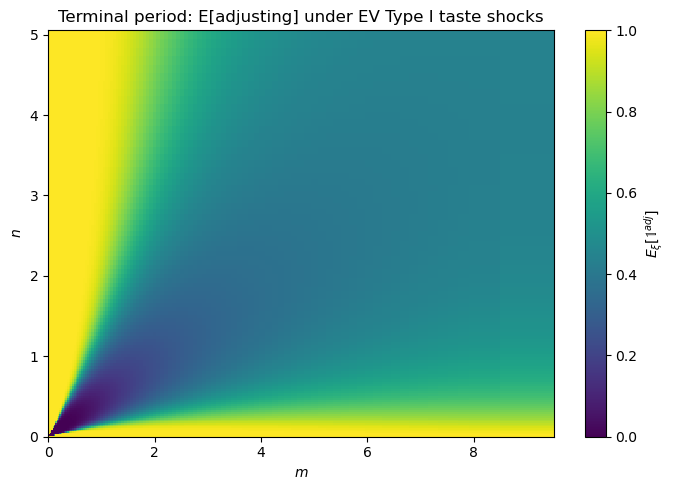

In [11]:
# --- Heatmap: expected adjustment probability over (n,m), terminal period ---
plot_adjusting_heatmap(
    nNrmGrid_T, mNrmGrid_T, barAdjProb_T_arr,
    title="Terminal period: E[adjusting] under EV Type I taste shocks",
    cbar_label=r"$E_\xi[\mathbb{1}^{adj}]$",
)


## Period $T-1$

1. End-of-period (post-decision) values using `use_expected` or `use_TransitionMatrix`,
   built from the EV-smoothed terminal continuation $v_T,v_{m,T},v_{n,T}$
2. Keeper via EGM + DCEGM upper envelope (unaffected by taste shocks)
3. Adjuster via FOC root-finding + `FUES_allPol` (unaffected by taste shocks)
4. EV Type I combine: log-sum inclusive value and logit-weighted policies / envelopes


### Income process

Built with the same truncated HANK engines as
`DurableModel_Fast_Latest.construct_lognormal_income_process_unemployment_truncated`
(`HANKIncShkDstn_Truncated`). For the basic model: permanent-shock std = 0 and
unemployment probability = 0, with truncation and `TranShkMean_Func` retained.

If `use_TransitionMatrix`, also build dense $m$/$b$ grids and `probGrid_income`
as in `updatemNrmGrid_income` / `updatebNrmGrid_income` / `updateBM_TranMatrix_numba`.


In [12]:
# ===== Exact income process (DurableModel_Fast_Latest) =====
IncShkDstn = HANKIncShkDstn_Truncated(
    sigma_Perm=PermShkStd,
    sigma_Tran=TranShkStd,
    n_approx_Perm=PermShkCount if PermShkStd > 0.0 else 1,
    n_approx_Tran=TranShkCount if TranShkStd > 0.0 else 1,
    UnempPrb=UnempPrb,
    IncUnemp=IncUnemp,
    taxrate=taxrate,
    TranShkMean_Func=TranShkMean_Func,
    labor=labor,
    wage=wage,
    truncation=truncation,
    neutral_measure=False,
)

ShkPrbsNext = IncShkDstn.pmv
PermShkValsNext = IncShkDstn.atoms[0]
TranShkValsNext = IncShkDstn.atoms[1]

# Permanent-only nodes (TransitionMatrix step 5 in the full solver)
PermShkValsNext_only = np.unique(PermShkValsNext)
ShkPrbsNext_PermShk = np.ones_like(PermShkValsNext_only) / len(PermShkValsNext_only)

TranShkMinNext = float(np.min(TranShkValsNext))
PermShkMinNext = float(np.min(PermShkValsNext))

print("Perm atoms:", np.unique(PermShkValsNext))
print("Tran atoms:", np.unique(np.round(TranShkValsNext, 6)))
print("E[psi] =", np.dot(ShkPrbsNext, PermShkValsNext))
print("E[theta] =", np.dot(ShkPrbsNext, TranShkValsNext))
print("n shocks =", len(ShkPrbsNext))

# --- TransitionMatrix grids / lottery (only built if selected) ---
if use_TransitionMatrix:
    # Same formulas as updatemNrmGrid_income / updatebNrmGrid_income with LTV=0
    mNrmMax_income = (
        Rfree / (PermGroFac * PermShkMinNext) * aXtraMax + float(np.max(TranShkValsNext))
    )
    mNrmGrid_income = make_grid_exp_mult(0.0001, mNrmMax_income, TranMatrix_mCount, timestonest=1)
    mNrmGrid_income = np.asarray(mNrmGrid_income).flatten()

    bNrmGrid_income = make_grid_exp_mult(0.0, mNrmMax_income - 1.0, TranMatrix_bCount, timestonest=1)
    bNrmGrid_income = np.asarray(bNrmGrid_income).flatten()

    # updateBM_TranMatrix_numba (UnempPrb=0 branch)
    IncUnemp_Std = 0.1
    mu_transformed = (1.0 - UnempPrb * IncUnemp) / (1.0 - UnempPrb) if UnempPrb < 1.0 else 1.0
    b_mesh, m_mesh = np.meshgrid(bNrmGrid_income, mNrmGrid_income, indexing="ij")
    diff_grid = m_mesh - b_mesh
    z = TranShkMean_Func(taxrate, labor, wage)
    probGrid_income = update_prob_grid_list_with_trunc(
        1,
        diff_grid,
        np.array([TranShkStd]),
        np.array([UnempPrb]),
        np.array([IncUnemp if UnempPrb > 0 else 1e-12]),
        np.array([mu_transformed]),
        np.array([TranShkMinNext]),
        np.array([z]),
        IncUnemp_Std,
    )[0]
    print("TransitionMatrix grids: m =", len(mNrmGrid_income), "b =", len(bNrmGrid_income))
    print("probGrid_income shape:", probGrid_income.shape)
else:
    mNrmGrid_income = None
    bNrmGrid_income = None
    probGrid_income = None
    print("TransitionMatrix grids not built (use_expected=True).")


Perm atoms: [1.]
Tran atoms: [0.6    0.7173 0.8356 0.9108 0.9804 1.0554 1.1507 1.3497]
E[psi] = 1.0
E[theta] = 0.9999999999999998
n shocks = 8
TransitionMatrix grids not built (use_expected=True).


### End-of-period functions

Laws of motion (basic model): $m'=\mathcal{R}a+\theta$, $n'=(1-\delta)d$
(with $\psi=G=1$, MaintCost=OpCost=0).

Integration method selected by the Booleans above:
- **`use_expected`**: `HARK.distribution.expected` with `vp_next_vPDFunc` / `vFunc_next`
  (same as `expected_method == "expected"` in `solve_DurableConsumer`)
- **`use_TransitionMatrix`**: $b\to m$ lottery (`probGrid_income`) then permanent-shock nodes
  (same as `expected_method == "TransitionMatrix"`, CPU path)


In [13]:
# ===== End-of-period values (exact branches from solve_DurableConsumer) =====
inv_vPFuncNext = inv_vPFunc_T
inv_vPDFuncNext = inv_vPDFunc_T
inv_vFunc_next = inv_vFunc_T

# a >= 0 => single interest factor (RSpread unused)
R_vec = np.full(len(aNrmGrid), Rfree)

post_shape = (len(dNrmGrid), len(aNrmGrid))
EndOfPrdvPOne = np.zeros(post_shape)
EndOfPrdvPTwo = np.zeros(post_shape)
EndOfPrdvPD = np.zeros(post_shape)
EndOfPrdv = np.zeros(post_shape)
inv_EndOfPrdv = np.zeros(post_shape)

if use_expected:
    # --- expected_method == "expected" ---
    for i_d in range(len(dNrmGrid)):
        EndOfPrdvPOne[i_d] = (
            DiscFac * LivPrb * PermGroFac ** (-CRRA) * R_vec
            * expected(
                vp_next_vPDFunc,
                IncShkDstn,
                args=(inv_vPFuncNext, aNrmGrid, dNrmGrid[i_d], CRRA, dDepr, R_vec, PermGroFac),
            )
        )
        EndOfPrdvPTwo[i_d] = (
            DiscFac * LivPrb * PermGroFac ** (-CRRA) * (R_vec + OpCost + MaintCost * dDepr)
            * expected(
                vp_next_vPDFunc,
                IncShkDstn,
                args=(inv_vPFuncNext, aNrmGrid, dNrmGrid[i_d], CRRA, dDepr, R_vec, PermGroFac),
            )
        )
        EndOfPrdvPD[i_d] = (
            DiscFac * LivPrb * PermGroFac ** (-CRRA) * (1.0 - dDepr * (1.0 - MaintCost))
            * expected(
                vp_next_vPDFunc,
                IncShkDstn,
                args=(inv_vPDFuncNext, aNrmGrid, dNrmGrid[i_d], CRRA, dDepr, R_vec, PermGroFac),
            )
        )
        EndOfPrdv[i_d] = (
            DiscFac * LivPrb
            * expected(
                vFunc_next,
                IncShkDstn,
                args=(utility_inv, inv_vFunc_next, aNrmGrid, dNrmGrid[i_d], CRRA, dDepr, R_vec, PermGroFac),
            )
        )
        inv_EndOfPrdv[i_d, 1:] = utility_inv(EndOfPrdv[i_d, 1:], CRRA)

elif use_TransitionMatrix:
    # --- expected_method == "TransitionMatrix" (CPU path) ---
    nNrmGridNow = dNrmGrid  # beginning-of-next-period n grid = end-of-period d grid
    _n2d = np.repeat(nNrmGridNow[:, np.newaxis], len(mNrmGrid_income), axis=1)
    _m2d = np.tile(mNrmGrid_income[np.newaxis, :], (len(nNrmGridNow), 1))

    inv_vPFuncNext_array = np.clip(inv_vPFuncNext(_n2d, _m2d), 0, None)
    inv_vPDFuncNext_array = np.clip(inv_vPDFuncNext(_n2d, _m2d), 0, None)
    inv_vFuncNext_array = np.clip(inv_vFunc_next(_n2d, _m2d), 0, None)

    vFuncNext_array = utility(inv_vFuncNext_array, CRRA)
    vPDFuncNext_array = inv_vPDFuncNext_array ** (-CRRA)
    vPFuncNext_array = inv_vPFuncNext_array ** (-CRRA)
    vPDFuncNext_array[np.isinf(vPDFuncNext_array)] = 1e16
    vPFuncNext_array[np.isinf(vPFuncNext_array)] = 1e16
    vFuncNext_array[np.isinf(vFuncNext_array)] = -1e16

    # Pre-multiply by lottery matrix: E[· | b, n]
    Interm_vP_array = np.dot(probGrid_income, vPFuncNext_array.T)    # (nB, nN)
    Interm_vPD_array = np.dot(probGrid_income, vPDFuncNext_array.T)
    Interm_v_array = np.dot(probGrid_income, vFuncNext_array.T)

    Interm_inv_vP_array = Interm_vP_array ** (-1.0 / CRRA)
    Interm_inv_vPD_array = Interm_vPD_array ** (-1.0 / CRRA)
    Interm_inv_v_array = utility_inv(Interm_v_array, CRRA)

    Interm_inv_vP_Interp_func = LinearFast(Interm_inv_vP_array, [bNrmGrid_income, nNrmGridNow])
    Interm_vPfunc_Integration = MargValueFuncCRRA(Interm_inv_vP_Interp_func, CRRA)
    Interm_inv_vPD_Interp_func = LinearFast(Interm_inv_vPD_array, [bNrmGrid_income, nNrmGridNow])
    Interm_vPDfunc_Integration = MargValueFuncCRRA(Interm_inv_vPD_Interp_func, CRRA)
    Interm_inv_v_Interp_func = LinearFast(Interm_inv_v_array, [bNrmGrid_income, nNrmGridNow])

    # Add zero / natural-borrowing point on b (LTV=0 => mNrmMin=0)
    BoroCnstNat2D_b = np.array([0.0 - TranShkMinNext])
    bNrmGrid_incomeNew = np.unique(np.sort(np.append(bNrmGrid_income, BoroCnstNat2D_b)))

    Interm_inv_vP_withzero_array = np.zeros((len(bNrmGrid_incomeNew), len(nNrmGridNow)))
    Interm_inv_vPD_withzero_array = np.zeros((len(bNrmGrid_incomeNew), len(nNrmGridNow)))
    Interm_inv_v_withzero_array = np.zeros((len(bNrmGrid_incomeNew), len(nNrmGridNow)))

    for i_n in range(len(nNrmGridNow)):
        n_aux_grid = np.ones(len(bNrmGrid_incomeNew)) * nNrmGridNow[i_n]
        idx = int(np.where(bNrmGrid_incomeNew >= BoroCnstNat2D_b[0])[0][0])
        b_slice = bNrmGrid_incomeNew[idx + 1 :]
        n_slice = n_aux_grid[idx + 1 :]
        Interm_inv_vP_withzero_array[idx + 1 :, i_n] = Interm_inv_vP_Interp_func(b_slice, n_slice)
        Interm_inv_vPD_withzero_array[idx + 1 :, i_n] = Interm_inv_vPD_Interp_func(b_slice, n_slice)
        Interm_inv_v_withzero_array[idx + 1 :, i_n] = Interm_inv_v_Interp_func(b_slice, n_slice)

    Interm_inv_vP_Interp_func = LinearFast(Interm_inv_vP_withzero_array, [bNrmGrid_incomeNew, nNrmGridNow])
    Interm_vPfunc_Integration = MargValueFuncCRRA(Interm_inv_vP_Interp_func, CRRA)
    Interm_inv_vPD_Interp_func = LinearFast(Interm_inv_vPD_withzero_array, [bNrmGrid_incomeNew, nNrmGridNow])
    Interm_vPDfunc_Integration = MargValueFuncCRRA(Interm_inv_vPD_Interp_func, CRRA)
    Interm_inv_v_Interp_func = LinearFast(Interm_inv_v_withzero_array, [bNrmGrid_incomeNew, nNrmGridNow])

    # Integrate permanent shocks (degenerate at 1 in the basic model)
    nD = len(dNrmGrid)
    nSh = len(PermShkValsNext_only)
    nA = len(aNrmGrid)

    _base_w = (
        ShkPrbsNext_PermShk
        * PermShkValsNext_only ** (-CRRA)
        * PermGroFac ** (-CRRA)
        * DiscFac
        * LivPrb
    )
    _base_wv = (
        ShkPrbsNext_PermShk
        * PermShkValsNext_only ** (1.0 - CRRA)
        * PermGroFac ** (1.0 - CRRA)
        * DiscFac
        * LivPrb
    )
    _d_surv = (1.0 - dDepr * (1.0 - MaintCost)) * dNrmGrid
    _d_lam = dNrmGrid * (OpCost + dDepr * MaintCost)

    n_next_3d = (
        _d_surv[:, np.newaxis, np.newaxis] / PermShkValsNext_only[np.newaxis, :, np.newaxis]
    ) * np.ones((1, 1, nA))
    b_next_3d = (
        (R_vec[np.newaxis, np.newaxis, :] * aNrmGrid[np.newaxis, np.newaxis, :]
         - _d_lam[:, np.newaxis, np.newaxis])
        / (PermGroFac * PermShkValsNext_only[np.newaxis, :, np.newaxis])
    )
    b_flat = b_next_3d.ravel()
    n_flat = n_next_3d.ravel()

    vP_flat = Interm_vPfunc_Integration(b_flat, n_flat)
    vPD_flat = Interm_vPDfunc_Integration(b_flat, n_flat)
    vinv_flat = np.clip(Interm_inv_v_Interp_func(b_flat, n_flat), 0.0, None)
    v_flat = utility(vinv_flat, CRRA)

    vP_3d = vP_flat.reshape(nD, nSh, nA)
    vPD_3d = vPD_flat.reshape(nD, nSh, nA)
    v_3d = v_flat.reshape(nD, nSh, nA)

    w = _base_w[np.newaxis, :, np.newaxis]
    wv = _base_wv[np.newaxis, :, np.newaxis]

    EndOfPrdvPOne = np.sum(w * R_vec[np.newaxis, np.newaxis, :] * vP_3d, axis=1)
    EndOfPrdvPTwo = np.sum(
        w * (R_vec + OpCost + MaintCost * dDepr)[np.newaxis, np.newaxis, :] * vP_3d, axis=1
    )
    EndOfPrdvPD = np.sum(w * (1.0 - dDepr * (1.0 - MaintCost)) * vPD_3d, axis=1)
    EndOfPrdv = np.sum(wv * v_3d, axis=1)
    inv_EndOfPrdv = utility_inv(EndOfPrdv, CRRA)

EndOfPrdvPOne[np.isnan(EndOfPrdvPOne)] = np.inf
EndOfPrdvPTwo[np.isnan(EndOfPrdvPTwo)] = np.inf
EndOfPrdvPD[np.isnan(EndOfPrdvPD)] = np.inf
inv_EndOfPrdv = np.nan_to_num(inv_EndOfPrdv, nan=0.0, posinf=0.0, neginf=0.0)

EndOfPrdvPOneFunc = LinearFast(EndOfPrdvPOne, [dNrmGrid, aNrmGrid])
EndOfPrdvPTwoFunc = LinearFast(EndOfPrdvPTwo, [dNrmGrid, aNrmGrid])
EndOfPrdvPDFunc = LinearFast(EndOfPrdvPD, [dNrmGrid, aNrmGrid])
inv_EndOfPrdvFunc = LinearFast(inv_EndOfPrdv, [dNrmGrid, aNrmGrid])
EndOfPrdvFunc = ValueFuncCRRA(inv_EndOfPrdvFunc, CRRA)

print("EoP method used:", "expected" if use_expected else "TransitionMatrix")
print("End-of-period arrays:", EndOfPrdvPOne.shape)


EoP method used: expected
End-of-period arrays: (100, 100)


### Keeper solution (EGM + DCEGM upper envelope)

In [14]:
# ===== Keeper: EGM + DCEGM (from solve_DurableConsumer keeper block) =====
vTransf = lambda x: np.exp(np.clip(x, -700, 700))
BoroCnstNat = 0.0  # a >= 0

cFuncKeepList = []
mKeepGrids = []

decreasing_segments_counter = 0
segments_total_counter = 0
for i_n, n0 in enumerate(dNrmGrid):
    n_aux = np.full(len(aNrmGrid), n0)
    EndOfPrdvPNow = EndOfPrdvPOne[i_n]
    EndOfPrdvNow = EndOfPrdv[i_n]

    cKeep_egm = CRRAutilityP_inv_njit(EndOfPrdvPNow, n_aux, alpha, d_ubar, CRRA)
    mKeep_egm = aNrmGrid + cKeep_egm
    vKeep_egm = CRRAutility_njit(cKeep_egm, n_aux, alpha, d_ubar, CRRA) + EndOfPrdvNow

    vKeept = vTransf(vKeep_egm)
    start, end = calc_nondecreasing_segments(mKeep_egm, vKeept)

    # Decreasing segments = breaks between nondecreasing pieces (= kinks)
    n_nondec = len(start)
    n_dec = max(n_nondec - 1, 0)
    decreasing_segments_counter += n_dec
    segments_total_counter += n_nondec + n_dec

    segments, m_segments, c_segments = [], [], []
    for j in range(len(start)):
        idx = range(start[j], end[j] + 1)
        segments.append([mKeep_egm[idx], vKeept[idx]])
        m_segments.append(mKeep_egm[idx])
        c_segments.append(cKeep_egm[idx])
    mKeep_upper, _, inds_upper = upper_envelope(segments)
    cKeep_upper = np.full_like(mKeep_upper, np.nan)
    for k, c_segm in enumerate(c_segments):
        if start[-1] + 1 == len(mKeep_egm):
            cKeep_upper = LinearFast(c_segments[0], [m_segments[0]])(mKeep_upper)
            break
        elif len(m_segments[k]) == 1:
            cKeep_upper[inds_upper == k] = c_segm
        else:
            cKeep_upper[inds_upper == k] = LinearFast(c_segm, [m_segments[k]])(
                mKeep_upper[inds_upper == k]
            )

    if cKeep_upper[0] != 0.0:
        c_interp = np.insert(cKeep_upper, 0, 0.0)
        m_interp = np.insert(mKeep_upper, 0, BoroCnstNat)
    else:
        c_interp, m_interp = cKeep_upper, mKeep_upper

    cFuncKeepList.append(LinearFast(c_interp, [m_interp]))
    mKeepGrids.append(m_interp)

###
print("Number of decreasing segments: ", decreasing_segments_counter)
print(
    "Share of decreasing segments: ",
    decreasing_segments_counter / segments_total_counter
    if segments_total_counter
    else float("nan"),
)

# Evaluate unconstrained keeper on common (n,m) grid
keep_shape = (len(nNrmGrid), len(mNrmGrid))
cFuncKeepUnc_arr = np.zeros(keep_shape)
dFuncKeepUnc_arr = np.zeros(keep_shape)
for i_n, n0 in enumerate(nNrmGrid):
    dFuncKeepUnc_arr[i_n, :] = n0
    cFuncKeepUnc_arr[i_n, :] = np.maximum(cFuncKeepList[i_n](mNrmGrid), 0.0)

cFuncKeepUnc = LinearFast(cFuncKeepUnc_arr, [nNrmGrid, mNrmGrid])
dFuncKeepUnc = LinearFast(dFuncKeepUnc_arr, [nNrmGrid, mNrmGrid])

# Constrained: c = m when a = 0 binds (LTV=0)
cFuncKeepCnst = LinearFast(
    np.array([[0.0, 1.0], [0.0, 1.0]]),
    [np.array([0.0, 1.0]), np.array([0.0, 1.0])],
)
cFuncKeep = LowerEnvelope2D(cFuncKeepUnc, cFuncKeepCnst, nan_bool=False)
dFuncKeep = dFuncKeepUnc
vPFuncKeep = MargValueFuncCRRA_dur(cFuncKeep, dFuncKeep, alpha, d_ubar, CRRA)

# Keeper value
inv_vFuncKeep_arr = np.zeros(keep_shape)
for i_n, n0 in enumerate(nNrmGrid):
    n_aux = np.full(len(mNrmGrid), n0)
    cNrm = np.clip(cFuncKeep(n_aux, mNrmGrid), 0.0, None)
    aNrm = np.maximum(mNrmGrid - cNrm, BoroCnstNat)
    vNrm = CRRAutility(cNrm, n_aux) + EndOfPrdvFunc(n_aux, aNrm)
    inv_vFuncKeep_arr[i_n, :] = utility_inv(vNrm, CRRA)

inv_vFuncKeep = LinearFast(inv_vFuncKeep_arr, [nNrmGrid, mNrmGrid])
vFuncKeep = ValueFuncCRRA(inv_vFuncKeep, CRRA)
aFuncKeep_arr = np.maximum(mNrmGrid[None, :] - cFuncKeepUnc_arr, 0.0)
# Use actual cFuncKeep for a
aFuncKeep_arr = np.zeros(keep_shape)
for i_n, n0 in enumerate(nNrmGrid):
    n_aux = np.full(len(mNrmGrid), n0)
    aFuncKeep_arr[i_n, :] = np.maximum(mNrmGrid - np.clip(cFuncKeep(n_aux, mNrmGrid), 0, None), 0.0)

vPFuncKeep_arr = CRRAutilityP(
    np.clip(np.array([cFuncKeep(np.full(len(mNrmGrid), n), mNrmGrid) for n in nNrmGrid]), 0, None),
    dFuncKeepUnc_arr,
)
vPDFuncKeep_arr = np.zeros(keep_shape)
for i_n, n0 in enumerate(nNrmGrid):
    n_aux = np.full(len(mNrmGrid), n0)
    cNrm = np.clip(cFuncKeep(n_aux, mNrmGrid), 0.0, None)
    aNrm = np.maximum(mNrmGrid - cNrm, 0.0)
    # keep_n envelope: u_d + beta(1-delta) E[v_n'] = u_d + EndOfPrdvPD(n,a)
    vPDFuncKeep_arr[i_n, :] = CRRAutilityPD(cNrm, n_aux) + EndOfPrdvPDFunc(n_aux, aNrm)

aFuncKeep = LinearFast(aFuncKeep_arr, [nNrmGrid, mNrmGrid])
vPDFuncKeep = LinearFast(vPDFuncKeep_arr, [nNrmGrid, mNrmGrid])
# vPFuncKeep already built above via MargValueFuncCRRA_dur(cFuncKeep, dFuncKeep, ...)
inv_vPFuncKeep = LinearFast(utilityP_inv(vPFuncKeep_arr, CRRA), [nNrmGrid, mNrmGrid])
inv_vPDFuncKeep = LinearFast(utilityP_inv(vPDFuncKeep_arr, CRRA), [nNrmGrid, mNrmGrid])

print("Keeper done.")


Number of decreasing segments:  0
Share of decreasing segments:  0.0
Keeper done.


c:\Users\amonninger\AppData\Local\miniconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:40: RuntimeWarning: divide by zero encountered in reciprocal
  return c ** (1.0 - rho) / (1.0 - rho)
C:\Users\amonninger\AppData\Local\Temp\ipykernel_13332\1342355393.py:74: RuntimeWarning: divide by zero encountered in power
  return (alpha * C ** (alpha * (1.0 - CRRA) - 1.0)
C:\Users\amonninger\AppData\Local\Temp\ipykernel_13332\1342355393.py:78: RuntimeWarning: divide by zero encountered in power
  return ((1.0 - alpha) * (C ** (alpha * (1.0 - CRRA)))


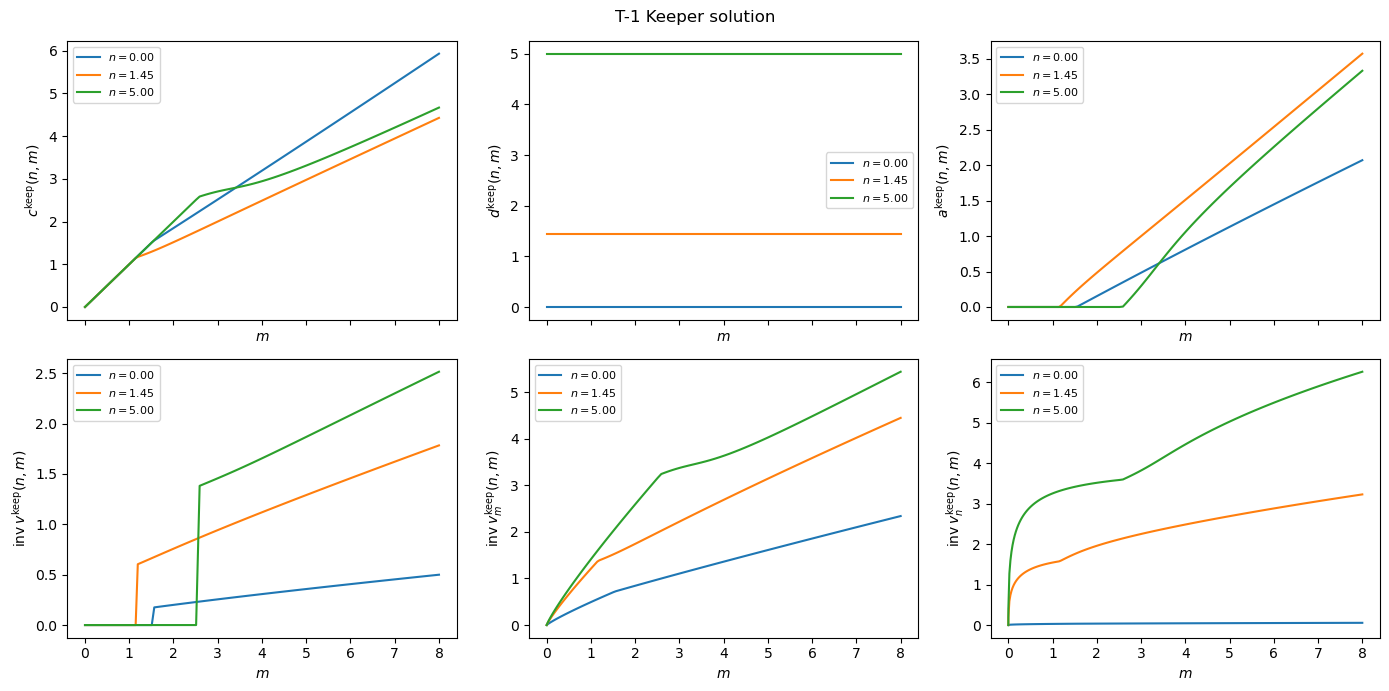

In [15]:
# --- Plot keeper solution only ---
n_show = nNrmGrid[np.linspace(1, len(nNrmGrid) - 1, 3, dtype=int)]

fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True)
funcs = [
    (cFuncKeep, r"$c^{\mathrm{keep}}(n,m)$"),
    (dFuncKeep, r"$d^{\mathrm{keep}}(n,m)$"),
    (aFuncKeep, r"$a^{\mathrm{keep}}(n,m)$"),
    (inv_vFuncKeep, r"$\mathrm{inv}\,v^{\mathrm{keep}}(n,m)$"),
    (inv_vPFuncKeep, r"$\mathrm{inv}\,v_m^{\mathrm{keep}}(n,m)$"),
    (inv_vPDFuncKeep, r"$\mathrm{inv}\,v_n^{\mathrm{keep}}(n,m)$"),
]
for ax, (func, ylab) in zip(axes.ravel(), funcs):
    for n0 in n_show:
        n_vec = np.full_like(mNrmGrid, n0, dtype=float)
        ax.plot(mNrmGrid, func(n_vec, mNrmGrid), label=fr"$n={n0:.2f}$")
    ax.set_ylabel(ylab)
    ax.set_xlabel(r"$m$")
    ax.legend(fontsize=8)

fig.suptitle("T-1 Keeper solution")
fig.tight_layout()
plt.show()


### Adjuster solution (root-finding + FUES)

FOC residual (MaintCost=OpCost=0):
$$0 = u_d(c,d) - \mathfrak{v}_c'(d,a) + \mathfrak{v}_d'(d,a),\quad c = u_c^{-1}(\mathfrak{v}_c'(d,a)).$$
Candidate roots are refined with `FUES_allPol` from `BackgroundInformation/FUES.py`, matching the full model.


In [16]:
# ===== Adjuster: FOC roots + FUES_allPol =====
def rootfinding_function(a, d):
    """FOC residual in a for fixed d (vectorized over a)."""
    a = np.atleast_1d(np.asarray(a, dtype=float))
    d = np.atleast_1d(np.asarray(d, dtype=float))
    if d.size == 1:
        d = np.full_like(a, float(np.asarray(d).ravel()[0]))
    eop1 = EndOfPrdvPOneFunc(d, a)
    eop2 = EndOfPrdvPTwoFunc(d, a)
    eopd = EndOfPrdvPDFunc(d, a)
    c = CRRAutilityP_inv_njit(eop1, d, alpha, d_ubar, CRRA)
    return CRRAutilityPD(c, d) - eop2 + eopd

a_min, a_max = float(aNrmGrid[0]), float(aNrmGrid[-1])
N_scan = 800
dNrmGridAdj = construct_grid(dNrmGrid[0], dNrmGrid[-1], len(xNrmGrid), grid_type, NestFac)
BoroCnstNat1D = 0.0  # a underbar / LTV = 0

aAdj_list, cAdj_list, xAdj_list, dAdj_list, vAdj_list = [], [], [], [], []

for d_aux in dNrmGridAdj:
    a_root = find_roots_in_interval(rootfinding_function, a_min, a_max, d_aux, N_scan)
    if a_root.size == 0:
        continue
    # a >= 0 (LTV=0, BoroCnstArt=0)
    a_root = a_root[a_root >= -1e-8]
    if a_root.size == 0:
        continue
    d_0 = np.full_like(a_root, d_aux)
    c_0 = CRRAutilityP_inv_njit(EndOfPrdvPOneFunc(d_0, a_root), d_0, alpha, d_ubar, CRRA)
    x_0 = a_root + d_0 + c_0
    v_0 = CRRAutility(c_0, d_0) + EndOfPrdvFunc(d_0, a_root)
    aAdj_list.append(a_root)
    cAdj_list.append(c_0)
    xAdj_list.append(x_0)
    dAdj_list.append(d_0)
    vAdj_list.append(v_0)

aAdj_array = np.concatenate(aAdj_list) if aAdj_list else np.array([])
cAdj_array = np.concatenate(cAdj_list) if cAdj_list else np.array([])
xAdj_array = np.concatenate(xAdj_list) if xAdj_list else np.array([])
dAdj_array = np.concatenate(dAdj_list) if dAdj_list else np.array([])
vAdj_array = np.concatenate(vAdj_list) if vAdj_list else np.array([])
print("Number of FOC roots:", len(xAdj_array))

# Same call signature / unpacking as DurableModel_Fast_Latest.py
xAdj_upper, vAdj_upper, cAdj_upper, dAdj_upper, aAdj_upper, _ = FUES_allPol(
    xAdj_array, vAdj_array, cAdj_array, dAdj_array, aAdj_array, b=BoroCnstNat1D
)
inv_vAdj_upper = utility_inv(vAdj_upper, CRRA)

print("Number of roots kept by FUES:", len(xAdj_upper))
print("Number of kinks removed:", len(xAdj_array) - len(xAdj_upper))
print("Share of removed points: ", (len(xAdj_array) - len(xAdj_upper))/len(xAdj_array) if len(xAdj_array) else float('nan'))

# Round first point slightly for numerical stability (as in full solver)
xAdj_upper[0] = np.round(xAdj_upper[0], decimals=3)
dAdj_upper[0] = np.round(dAdj_upper[0], decimals=3)
aAdj_upper[0] = np.round(aAdj_upper[0], decimals=3)
cAdj_upper[0] = np.round(cAdj_upper[0], decimals=3)
inv_vAdj_upper[0] = np.round(inv_vAdj_upper[0], decimals=3)

# Add natural borrowing / zero point
x_upper = np.append(BoroCnstNat1D, xAdj_upper)
d_upper = np.append(0.0, dAdj_upper)
c_upper = np.append(0.0, cAdj_upper)
a_upper = np.append(BoroCnstNat1D, aAdj_upper)
inv_v_upper = np.append(0.0, inv_vAdj_upper)

# Clean non-monotone tail
while len(x_upper) > 2 and (
    c_upper[-1] < c_upper[-2] or d_upper[-1] < d_upper[-2] or inv_v_upper[-1] < inv_v_upper[-2]
):
    x_upper, c_upper, d_upper, a_upper, inv_v_upper = (
        x_upper[:-1], c_upper[:-1], d_upper[:-1], a_upper[:-1], inv_v_upper[:-1]
    )

cFuncAdj = LinearFast(c_upper, [x_upper])
dFuncAdj = LinearFast(d_upper, [x_upper])
aFuncAdj = LinearFast(a_upper, [x_upper])
# inv_vFuncAdj_1d = LinearFast(inv_v_upper, [x_upper])
# vFuncAdj = ValueFuncCRRA(inv_vFuncAdj_1d, CRRA)
vPFuncAdj = MargValueFuncCRRA_dur(cFuncAdj, dFuncAdj, alpha, d_ubar, CRRA)
vPD_upper = CRRAutilityPD(c_upper, d_upper)
vP_upper = CRRAutilityP(c_upper, d_upper)
vPDFuncAdj_1d = LinearFast(vPD_upper, [x_upper])
inv_vPFuncAdj_1d = LinearFast(utilityP_inv(vP_upper, CRRA), [x_upper])
inv_vPDFuncAdj_1d = LinearFast(utilityP_inv(vPD_upper, CRRA), [x_upper])

print("Adjuster 1-D functions built. x range:", x_upper[0], "->", x_upper[-1])


Number of FOC roots: 144
Number of roots kept by FUES: 144
Number of kinks removed: 0
Share of removed points:  0.0
Adjuster 1-D functions built. x range: 0.0 -> 17.681504723795534


C:\Users\amonninger\AppData\Local\Temp\ipykernel_13332\1342355393.py:78: RuntimeWarning: divide by zero encountered in power
  return ((1.0 - alpha) * (C ** (alpha * (1.0 - CRRA)))
C:\Users\amonninger\AppData\Local\Temp\ipykernel_13332\1342355393.py:74: RuntimeWarning: divide by zero encountered in power
  return (alpha * C ** (alpha * (1.0 - CRRA) - 1.0)


In [17]:
### inv_vAdj func
c_aux = cFuncAdj(xNrmGrid)
d_aux = dFuncAdj(xNrmGrid)
a_aux = xNrmGrid - d_aux - c_aux
vAdj_aux = CRRAutility(c_aux, d_aux) + EndOfPrdvFunc(d_aux, a_aux)
inv_vAdj_aux_array = utility_inv(vAdj_aux, CRRA)

inv_vFuncAdj_1d = LinearFast(inv_vAdj_aux_array, [xNrmGrid])
vFuncAdj = ValueFuncCRRA(inv_vFuncAdj_1d, CRRA)

c:\Users\amonninger\AppData\Local\miniconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:40: RuntimeWarning: divide by zero encountered in reciprocal
  return c ** (1.0 - rho) / (1.0 - rho)


C:\Users\amonninger\AppData\Local\Temp\ipykernel_13332\1342355393.py:74: RuntimeWarning: divide by zero encountered in power
  return (alpha * C ** (alpha * (1.0 - CRRA) - 1.0)


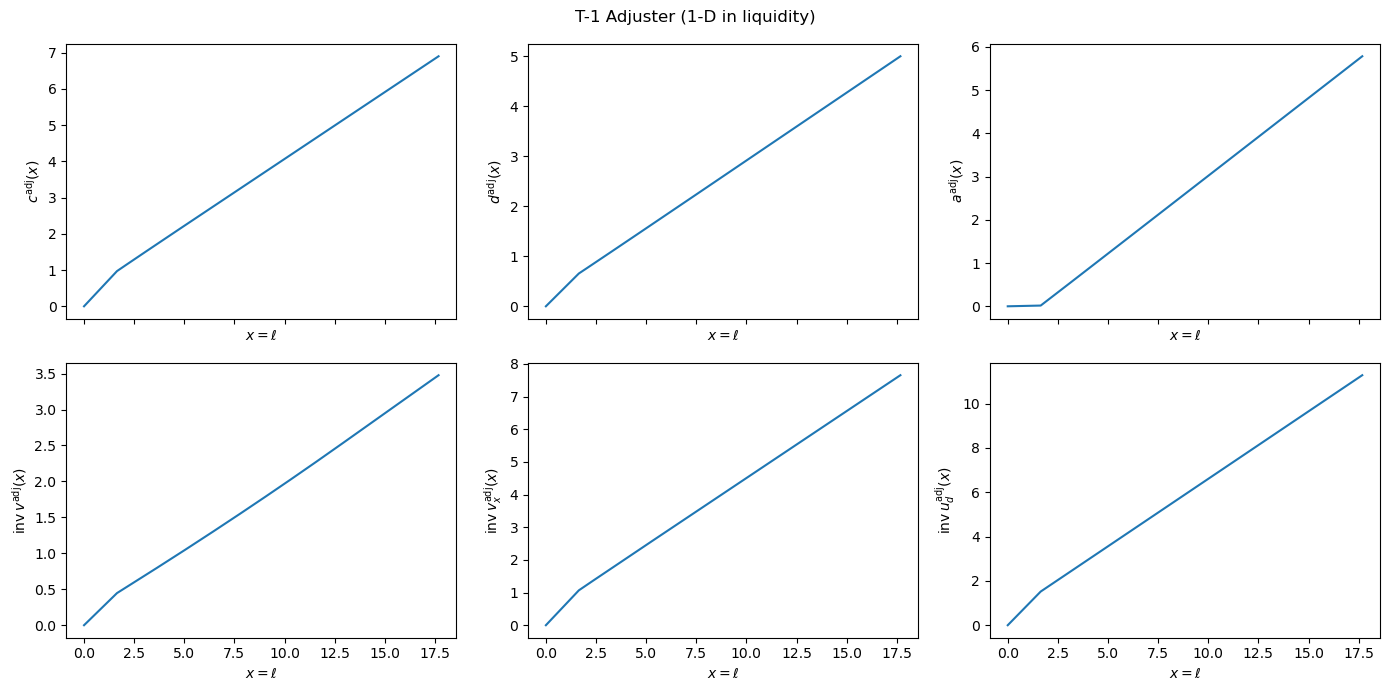

In [18]:
# Map adjuster onto (n,m) for the later combine step
cFuncAdj_NM_arr = np.zeros(keep_shape)
dFuncAdj_NM_arr = np.zeros(keep_shape)
aFuncAdj_NM_arr = np.zeros(keep_shape)
inv_vFuncAdj_NM_arr = np.zeros(keep_shape)
vPFuncAdj_NM_arr = np.zeros(keep_shape)
vPDFuncAdj_NM_arr = np.zeros(keep_shape)

for i_n, n0 in enumerate(nNrmGrid):
    n_aux = np.full(len(mNrmGrid), n0)
    tau_nm = tau_func(n_aux + mNrmGrid)
    x_aux = np.clip(mNrmGrid + (1.0 - tau_nm) * n_aux, 0.0, None)
    cFuncAdj_NM_arr[i_n, :] = np.maximum(cFuncAdj(x_aux), 0.0)
    dFuncAdj_NM_arr[i_n, :] = np.maximum(dFuncAdj(x_aux), 0.0)
    aFuncAdj_NM_arr[i_n, :] = np.maximum(x_aux - cFuncAdj_NM_arr[i_n] - dFuncAdj_NM_arr[i_n], 0.0)
    inv_vFuncAdj_NM_arr[i_n, :] = inv_vFuncAdj_1d(x_aux)
    vPFuncAdj_NM_arr[i_n, :] = CRRAutilityP(cFuncAdj_NM_arr[i_n], dFuncAdj_NM_arr[i_n])
    vPDFuncAdj_NM_arr[i_n, :] = (1.0 - tau_nm) * vPFuncAdj_NM_arr[i_n]

cFuncAdj_NM = LinearFast(cFuncAdj_NM_arr, [nNrmGrid, mNrmGrid])
dFuncAdj_NM = LinearFast(dFuncAdj_NM_arr, [nNrmGrid, mNrmGrid])

# Map adjuster onto (n,m) for the later combine step
cFuncAdj_NM_arr = np.zeros(keep_shape)
dFuncAdj_NM_arr = np.zeros(keep_shape)
aFuncAdj_NM_arr = np.zeros(keep_shape)
inv_vFuncAdj_NM_arr = np.zeros(keep_shape)
vPFuncAdj_NM_arr = np.zeros(keep_shape)
vPDFuncAdj_NM_arr = np.zeros(keep_shape)

for i_n, n0 in enumerate(nNrmGrid):
    n_aux = np.full(len(mNrmGrid), n0)
    tau_nm = tau_func(n_aux + mNrmGrid)
    x_aux = np.clip(mNrmGrid + (1.0 - tau_nm) * n_aux, 0.0, None)
    cFuncAdj_NM_arr[i_n, :] = np.maximum(cFuncAdj(x_aux), 0.0)
    dFuncAdj_NM_arr[i_n, :] = np.maximum(dFuncAdj(x_aux), 0.0)
    aFuncAdj_NM_arr[i_n, :] = np.maximum(x_aux - cFuncAdj_NM_arr[i_n] - dFuncAdj_NM_arr[i_n], 0.0)
    inv_vFuncAdj_NM_arr[i_n, :] = inv_vFuncAdj_1d(x_aux)
    vPFuncAdj_NM_arr[i_n, :] = CRRAutilityP(cFuncAdj_NM_arr[i_n], dFuncAdj_NM_arr[i_n])
    vPDFuncAdj_NM_arr[i_n, :] = (1.0 - tau_nm) * vPFuncAdj_NM_arr[i_n]

cFuncAdj_NM = LinearFast(cFuncAdj_NM_arr, [nNrmGrid, mNrmGrid])
dFuncAdj_NM = LinearFast(dFuncAdj_NM_arr, [nNrmGrid, mNrmGrid])

# --- Plot one-dimensional adjuster policies over liquidity x ---
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True)
funcs_1d = [
    (cFuncAdj, r"$c^{\mathrm{adj}}(x)$"),
    (dFuncAdj, r"$d^{\mathrm{adj}}(x)$"),
    (aFuncAdj, r"$a^{\mathrm{adj}}(x)$"),
    (inv_vFuncAdj_1d, r"$\mathrm{inv}\,v^{\mathrm{adj}}(x)$"),
    (inv_vPFuncAdj_1d, r"$\mathrm{inv}\,v_x^{\mathrm{adj}}(x)$"),
    (inv_vPDFuncAdj_1d, r"$\mathrm{inv}\,u_d^{\mathrm{adj}}(x)$"),
]
for ax, (func, ylab) in zip(axes.ravel(), funcs_1d):
    ax.plot(x_upper, func(x_upper))
    ax.set_ylabel(ylab)
    ax.set_xlabel(r"$x=\ell$")

fig.suptitle("T-1 Adjuster (1-D in liquidity)")
fig.tight_layout()
plt.show()


### Combining solutions (EV Type I log-sum / logit)


T-1 EV taste-shock combine done. E[P^adj]: 0.6539984538291532


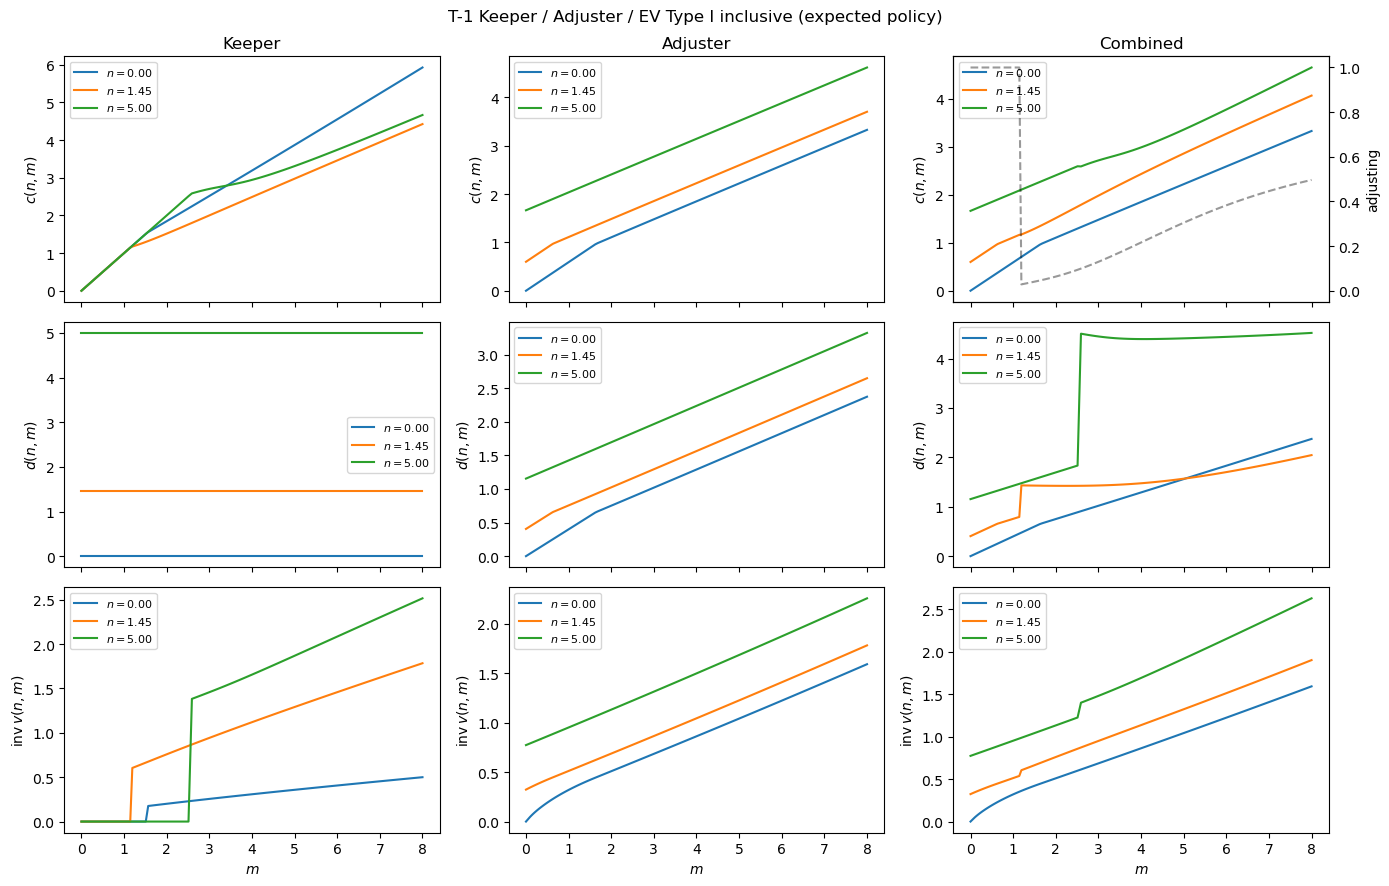

In [19]:
# ===== T-1: EV Type I taste-shock combine =====
cKeep_arr = np.zeros(keep_shape)
dKeep_arr = np.zeros(keep_shape)
for i_n, n0 in enumerate(nNrmGrid):
    n_aux = np.full(len(mNrmGrid), n0)
    cKeep_arr[i_n, :] = np.clip(cFuncKeep(n_aux, mNrmGrid), 0.0, None)
    dKeep_arr[i_n, :] = n0

vAdj_level = utility(inv_vFuncAdj_NM_arr, CRRA)
vKeep_level = utility(inv_vFuncKeep_arr, CRRA)

(
    barV_arr, barVP_arr, barVPD_arr,
    barC_arr, barD_arr, barA_arr, barAdjProb_arr,
) = combine_ev_taste_shock(
    vAdj_level, vKeep_level,
    cFuncAdj_NM_arr, dFuncAdj_NM_arr, aFuncAdj_NM_arr, vPFuncAdj_NM_arr, vPDFuncAdj_NM_arr,
    cKeep_arr, dKeep_arr, aFuncKeep_arr, vPFuncKeep_arr, vPDFuncKeep_arr,
    sigma_eps,
)

cFunc = LinearFast(barC_arr, [nNrmGrid, mNrmGrid])   # expected policy (plotting only)
dFunc = LinearFast(barD_arr, [nNrmGrid, mNrmGrid])   # expected policy (plotting only)
inv_vFunc = LinearFast(utility_inv(barV_arr, CRRA), [nNrmGrid, mNrmGrid])
vFunc = ValueFuncCRRA(inv_vFunc, CRRA)
vPFunc = LinearFast(barVP_arr, [nNrmGrid, mNrmGrid])
vPDFunc = LinearFast(barVPD_arr, [nNrmGrid, mNrmGrid])
adjusting = LinearFast(barAdjProb_arr, [nNrmGrid, mNrmGrid])  # P^adj

print("T-1 EV taste-shock combine done. E[P^adj]:", barAdjProb_arr.mean())

plot_keeper_adjuster_combined(
    n_show, mNrmGrid,
    cFuncKeep, dFuncKeep, inv_vFuncKeep,
    cFuncAdj_NM, dFuncAdj_NM, LinearFast(inv_vFuncAdj_NM_arr, [nNrmGrid, mNrmGrid]),
    cFunc, dFunc, inv_vFunc,
    adjusting=adjusting,
    title="T-1 Keeper / Adjuster / EV Type I inclusive (expected policy)",
)



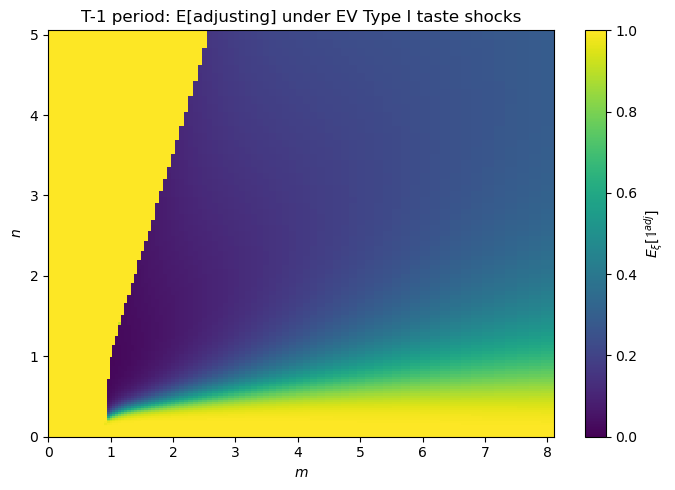

In [20]:
# --- Heatmap: expected adjustment probability over (n,m), T-1 ---
plot_adjusting_heatmap(
    nNrmGrid, mNrmGrid, barAdjProb_arr,
    title="T-1 period: E[adjusting] under EV Type I taste shocks",
    cbar_label=r"$E_\xi[\mathbb{1}^{adj}]$",
)


### Quick sanity checks

In [21]:
# Assets nonnegative; logit adjustment probability in (0,1) away from hard corners
# when sigma_eps > 0 (EV Type I smooths the discrete choice).
assert np.nanmin(barA_arr) >= -1e-8
assert np.nanmin(barAdjProb_arr) >= -1e-8 and np.nanmax(barAdjProb_arr) <= 1.0 + 1e-8
assert sigma_eps == 0.0 or not set(np.unique(np.round(barAdjProb_arr, 6))).issubset({0.0, 1.0}), (
    "With sigma_eps > 0 the logit adjustment probability should be strictly interior "
    "somewhere (EV Type I should smooth the discrete choice)."
)

n_mid = float(nNrmGrid[len(nNrmGrid) // 3])
m_low = float(mNrmGrid[2])
m_high = float(mNrmGrid[-5])
print(
    f"At (n,m)=({n_mid:.3f},{m_low:.3f}): "
    f"P(adj)={float(adjusting(n_mid, m_low)):.3f}, "
    f"E[c]={float(cFunc(n_mid, m_low)):.3f}, E[d]={float(dFunc(n_mid, m_low)):.3f}"
)
print(
    f"At (n,m)=({n_mid:.3f},{m_high:.3f}): "
    f"P(adj)={float(adjusting(n_mid, m_high)):.3f}, "
    f"E[c]={float(cFunc(n_mid, m_high)):.3f}, E[d]={float(dFunc(n_mid, m_high)):.3f}"
)


At (n,m)=(0.796,0.024): P(adj)=1.000, E[c]=0.343, E[d]=0.232
At (n,m)=(0.796,7.228): P(adj)=0.736, E[c]=3.454, E[d]=1.913
